# IT4060 - Machine Learning
## Lab 4 - Optimizing Linear Regression
### Part B - Student Exercise: California Housing

Complete the TODO sections in this notebook using the workflow demonstrated in **Part A**. Do not begin with `LinearRegression`; use it only later as a verification step.

**Submission:** Submit this completed notebook with all outputs visible.

## Setup

The helper functions below are the same functions demonstrated in Part A. They are included here so this notebook can run independently.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge

np.set_printoptions(suppress=True, precision=4)

def compute_cost(X, y, theta):
    m = len(y)
    error = X @ theta - y
    return float(((error.T @ error) / (2 * m)).item())

def gradient_descent(X, y, theta, alpha=0.1, iterations=500, stop_on_nonfinite=True):
    m = len(y)
    history = []
    theta = theta.astype(float).copy()

    for i in range(iterations):
        error = X @ theta - y
        gradient = (X.T @ error) / m
        theta = theta - alpha * gradient
        cost = compute_cost(X, y, theta)
        history.append(cost)

        if stop_on_nonfinite and not np.isfinite(cost):
            print(f'Stopped at iteration {i + 1}: cost became non-finite.')
            break

    return theta, np.asarray(history)


### B1. Load and inspect the dataset

In [21]:
from sklearn.datasets import fetch_california_housing

cal = fetch_california_housing(as_frame=True)
X_cal = cal.data.copy()
y_cal = cal.target.copy()

print('Shape:', X_cal.shape)
print('Features:', list(X_cal.columns))
X_cal.describe().loc[['min','max','mean','std']]


Shape: (20640, 8)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532


### B2. Train-test split

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_cal, y_cal, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)


(16512, 8) (4128, 8)


### B3. Standardize using training statistics only

In [23]:
# TODO: Calculate training means and standard deviations.
# TODO: Standardize X_train and X_test using the SAME training statistics.
# Suggested variable names: mu_cal, sigma_cal, X_train_scaled, X_test_scaled

mu_cal = X_train.mean()
sigma_cal = X_train.std()

X_train_scaled = (X_train - mu_cal) / sigma_cal
X_test_scaled = (X_test - mu_cal) / sigma_cal

### B4. Add the intercept column and initialize theta

In [24]:
# TODO: Convert the scaled data to NumPy arrays if needed.
# TODO: Add a leading column of ones to training and test matrices.
# TODO: Reshape y_train and y_test into column vectors.
# TODO: Initialize theta with zeros.
# Print the shapes of X_train_b and theta.

X_tr = X_train_scaled.to_numpy()
X_te = X_test_scaled.to_numpy()

X_train_b = np.hstack([np.ones((X_tr.shape[0], 1)), X_tr])
X_test_b = np.hstack([np.ones((X_te.shape[0], 1)), X_te])

y_train_vec = y_train.to_numpy().reshape(-1, 1)
y_test_vec = y_test.to_numpy().reshape(-1, 1)

theta_init = np.zeros((X_train_b.shape[1], 1))

print('X_train_b shape:', X_train_b.shape)
print('theta shape:', theta_init.shape)

X_train_b shape: (16512, 9)
theta shape: (9, 1)


### B5. Train using gradient descent

Initial Cost: 2.3389
Final Cost: 0.2590


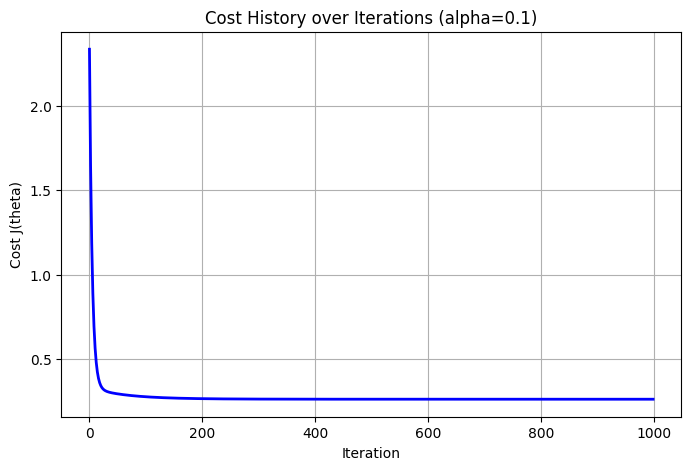

In [33]:
# TODO: Reuse gradient_descent(...) from Part A.
# Start with alpha=0.1 and iterations=1000.
# Store the learned theta and cost history.
# Print the initial and final cost.

theta_gd, cost_history = gradient_descent(
    X_train_b, y_train_vec, theta_init, alpha=0.1, iterations=1000
)

print(f'Initial Cost: {cost_history[0]:.4f}')
print(f'Final Cost: {cost_history[-1]:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(cost_history, color='blue', linewidth=2)
plt.title('Cost History over Iterations (alpha=0.1)')
plt.xlabel('Iteration')
plt.ylabel('Cost J(theta)')
plt.grid(True)
plt.show()

In [26]:
# TODO: Plot cost against iteration number.

theta_gd, cost_history = gradient_descent(
    X_train_b, y_train_vec, theta_init, alpha=0.1, iterations=1000
)

print(f'Initial Cost: {cost_history[0]:.4f}')
print(f'Final Cost: {cost_history[-1]:.4f}')

Initial Cost: 2.3389
Final Cost: 0.2590


### B6. Learning-rate experiment

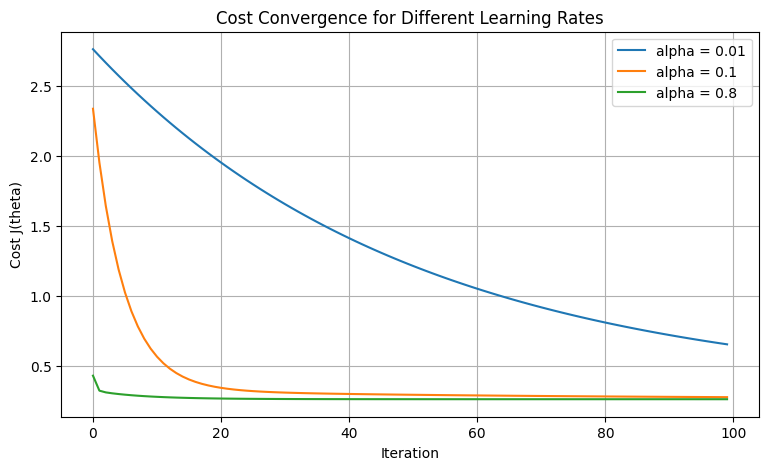

In [34]:
# TODO: Test at least three learning rates, for example 0.01, 0.1 and 0.8.
# Plot the cost histories on the same figure.
# Select a stable learning rate for the remaining tasks.

learning_rates = [0.01, 0.1, 0.8]
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    _, hist = gradient_descent(X_train_b, y_train_vec, theta_init, alpha=lr, iterations=100)
    plt.plot(hist, label=f'alpha = {lr}')

plt.title('Cost Convergence for Different Learning Rates')
plt.xlabel('Iteration')
plt.ylabel('Cost J(theta)')
plt.legend()
plt.grid(True)
plt.show()

### B7. Test-set prediction and RMSE

In [36]:
from sklearn.metrics import mean_squared_error

# TODO: Use the selected gradient-descent theta to predict X_test_b.
# TODO: Calculate test RMSE.

y_pred_gd = X_test_b @ theta_gd
rmse_gd = np.sqrt(mean_squared_error(y_test_vec, y_pred_gd))
print(f'Gradient Descent Test RMSE: {rmse_gd:.4f}')

Gradient Descent Test RMSE: 0.7457


### B8. Normal equation

In [35]:
# TODO: Compute theta using the pseudoinverse / normal equation on the TRAINING design matrix.
# TODO: Predict the test set and calculate RMSE.

theta_ne = np.linalg.pinv(X_train_b) @ y_train_vec
y_pred_ne = X_test_b @ theta_ne
rmse_ne = np.sqrt(mean_squared_error(y_test_vec, y_pred_ne))
print(f'Normal Equation Test RMSE: {rmse_ne:.4f}')

Normal Equation Test RMSE: 0.7456


### B9. Verify with scikit-learn

In [37]:
# TODO: Fit LinearRegression on the standardized training features (without your added intercept column).
# TODO: Predict the standardized test features and calculate RMSE.
# TODO: Display the three RMSE values together: GD, normal equation, sklearn.

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_sk = lr_model.predict(X_test_scaled)
rmse_sk = np.sqrt(mean_squared_error(y_test, y_pred_sk))

rmse_comparison = pd.DataFrame({
    'Method': ['Gradient Descent', 'Normal Equation', 'Scikit-Learn'],
    'Test RMSE': [rmse_gd, rmse_ne, rmse_sk]
})
print('RMSE Comparison')
print(rmse_comparison)

RMSE Comparison
             Method  Test RMSE
0  Gradient Descent   0.745653
1   Normal Equation   0.745581
2      Scikit-Learn   0.745581


### B10. Ridge regularization

In [38]:
# TODO: Fit Ridge models using at least lambda = 0.01, 1, and 100.
# For each model, record:
#   1) test RMSE
#   2) L2 norm of the coefficient vector
# Display the results in a pandas DataFrame.

alphas = [0.01, 1, 100]
ridge_results = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scaled, y_train)
    preds = ridge.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    l2_norm = np.linalg.norm(ridge.coef_)

    ridge_results.append({
        'Lambda (alpha)': a,
        'Test RMSE': rmse,
        'L2 Norm of Coeffs': l2_norm
    })

print('Ridge Regularization Results')
print(pd.DataFrame(ridge_results))

Ridge Regularization Results
   Lambda (alpha)  Test RMSE  L2 Norm of Coeffs
0            0.01   0.745581           1.584191
1            1.00   0.745557           1.583231
2          100.00   0.743819           1.495541


## End of Part B

Save the notebook with all TODOs completed and outputs visible.

**Suggested filename:** `REGNO_Lab04.ipynb`